# Option C: County swing, 2020 to 2024

Data: `data/medsl/countypres_2000-2024.csv`. Instructions are on Canvas. Don't edit anything in `data/`.


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. Load

In [2]:
import pandas as pd

df = pd.read_csv("../data/medsl/countypres_2000-2024.csv")

print(df.head())



     state county_name  year state_po  county_fips        office  \
0  ALABAMA     AUTAUGA  2024       AL       1001.0  US PRESIDENT   
1  ALABAMA     AUTAUGA  2024       AL       1001.0  US PRESIDENT   
2  ALABAMA     AUTAUGA  2024       AL       1001.0  US PRESIDENT   
3  ALABAMA     AUTAUGA  2024       AL       1001.0  US PRESIDENT   
4  ALABAMA     BALDWIN  2024       AL       1003.0  US PRESIDENT   

         candidate        party  candidatevotes  totalvotes   version   mode  
0            OTHER        OTHER           293.0       28281  20260225  TOTAL  
1     CHASE OLIVER  LIBERTARIAN            65.0       28281  20260225  TOTAL  
2  KAMALA D HARRIS     DEMOCRAT          7439.0       28281  20260225  TOTAL  
3   DONALD J TRUMP   REPUBLICAN         20484.0       28281  20260225  TOTAL  
4            OTHER        OTHER          1276.0      122249  20260225  TOTAL  


## 2. Validate
Row counts, missing-value flags, duplicates, date ranges. Show your checks.

In [3]:
import pandas as pd

df = pd.read_csv("../data/medsl/countypres_2000-2024.csv")

print("file loaded")

#checking total rows and columns
print("Total Rows", len(df))
print("Total Columns", len(df.columns))

#to check missing values and flag them

missing_values = df.isnull().sum()

print("missing values:")
print(missing_values)

missing_flags = missing_values > 0

print("\nMissing_value flags:")
print(missing_flags)

#now to check duplicates
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

#validating date ranges


print("Earliest date", df["year"].min())
print("Latest date", df["year"].max())

#checking and flagging dates
invalid_dates = df["year"].isna().sum()
print("Invalid or missing dates:", invalid_dates)

file loaded
Total Rows 94151
Total Columns 12
missing values:
state                0
county_name          0
year                 0
state_po             0
county_fips         52
office               0
candidate            0
party              501
candidatevotes      37
totalvotes           0
version              0
mode              2795
dtype: int64

Missing_value flags:
state             False
county_name       False
year              False
state_po          False
county_fips        True
office            False
candidate         False
party              True
candidatevotes     True
totalvotes        False
version           False
mode               True
dtype: bool
Number of duplicate rows: 83
Earliest date 2000
Latest date 2024
Invalid or missing dates: 0


## 3. First target

counties only in 2020:
      county_fips         state    county_name
81539     2938000      MISSOURI    KANSAS CITY
88412       46102  SOUTH DAKOTA  OGLALA LAKOTA
counties only in 2024:
      county_fips         state    county_name
9175        36000      MISSOURI    KANSAS CITY
16291       46113  SOUTH DAKOTA  OGLALA LAKOTA
Number of counties: 3111
Median shift: 1.5517903223803415

Top 10 Republican shifts:
     state_po county_name      shift
2514       TX    MAVERICK  13.441699
169        CA    IMPERIAL  12.894622
2595       TX        WEBB  12.296162
1663       NY       BRONX  11.272508
1701       NY      QUEENS  10.495785
2569       TX       STARR  10.242591
1655       NJ     PASSAIC   9.865180
2419       TX      DIMMIT   9.536151
333        FL  MIAMI-DADE   9.460937
2463       TX     HIDALGO   9.341452

Top 10 Republican decreases:
     state_po county_name     shift
820        IA     MAHASKA -7.593931
432        GA       HENRY -4.594377
2506       TX      LOVING -4.215116
271   

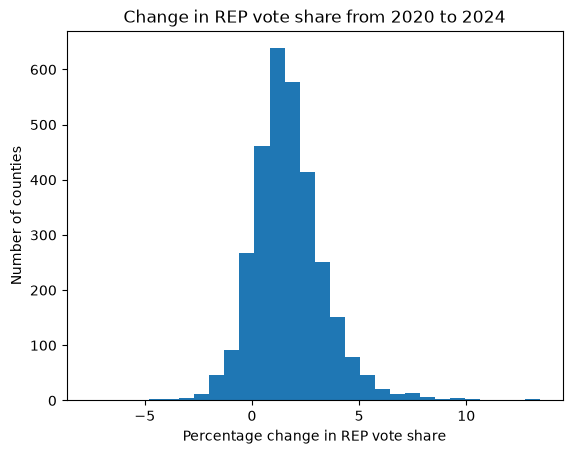

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("../data/medsl/countypres_2000-2024.csv")

#filtering to just keep the election results
data = data[data["year"].isin([2020, 2024])]

#removing alaska due to how they count vote share
data = data[data["state_po"] != "AK"]

#filtering out parties besides REP and DEM
data = data[data["party"].isin(["REPUBLICAN", "DEMOCRAT"])]

#removing data without a fips
data = data.dropna(subset=["county_fips"])

#making fips 5 digits
data["county_fips"] = data["county_fips"].astype(int).astype(str).str.zfill(5)

#adding the votes
votes = data.groupby(["county_fips", "year", "party"])["candidatevotes"].sum()

#separating the votes
votes = votes.unstack("party", fill_value=0)

#calculating two party share
votes["rep_share"] = (votes["REPUBLICAN"] / (votes["REPUBLICAN"] + votes["DEMOCRAT"])) * 100

#separating the votes by year
shares = votes["rep_share"].unstack("year")

#lsit of countys with 2020 data
counties_2020 = data[data["year"] == 2020][["county_fips", "state", "county_name"]].drop_duplicates()

#now for 2024
counties_2024 = data[data["year"] == 2024][["county_fips", "state", "county_name"]].drop_duplicates()

#finding counties with missing data
only_2020 = counties_2020[~counties_2020["county_fips"].isin(counties_2024["county_fips"])]
only_2024 = counties_2024[~counties_2024["county_fips"].isin(counties_2020["county_fips"])]
print("counties only in 2020:")
print(only_2020)
print("counties only in 2024:")
print(only_2024)

#keeping data that only has values for both years
shares = shares.dropna(subset=[2020, 2024])

#getting the names associated with the fips
county_names = data[data["year"] == 2024][["county_fips", "state", "state_po", "county_name"]].drop_duplicates("county_fips")

county_names = county_names.set_index("county_fips")

#joining the county names to the shares
results = county_names.join(shares)

#Calculating the change in vote share
results["shift"] = results[2024] - results[2020]

#moving the fips back to column
results = results.reset_index()
results = results.dropna()
results = results.rename(columns={"county_fips": "fips", 2020: "r_share_2020", 2024 : "r_share_2024"})
results = results[["county_name", "fips", "r_share_2020", "r_share_2024", "shift", "state_po"]]

#making a new csv
results.to_csv("../results/county_shifts.csv", index=False)

print("Number of counties:", len(results))

print("Median shift:", results["shift"].median())

print("\nTop 10 Republican shifts:")
print(results.nlargest(10, "shift")[["state_po", "county_name", "shift"]])
print("\nTop 10 Republican decreases:")
print(results.nsmallest(10, "shift")[["state_po", "county_name", "shift"]])
plt.hist(results["shift"], bins=30)
plt.title("Change in REP vote share from 2020 to 2024")
plt.xlabel("Percentage change in REP vote share")
plt.ylabel("Number of counties")
plt.show()

### Short explanation
(Write your answer here, in Markdown.)

My code found that that Kansas City, Missouri and Oglala Lakota, South Dakota had issues. I believe that the issues came from how the fip numbers were processed. With kansas city it appears that the zeros were not formatted correctly and not removed when turning the fips into 5 digits or the zero was removed at the start because i treated it as an integer. And for Oglala i noticed that the fips was reported under a different catagory for 2024 leading to the data being missing.

## 4. Write your results
Fill in your section of `results.json`, then run `python check_results.py` in the terminal.

In [ ]:
with open("../results.json") as f:
    results = json.load(f)

results["option"] = "C"
# results["C_medsl"]["..."] = ...

with open("../results.json", "w") as f:
    json.dump(results, f, indent=2)


## 5. Exploration
State your question, then your analysis and figures. Explain what you find in Markdown cells as you go.

### Interpretation
About 400–800 words. Tie each claim to evidence.

### Limitations
What could be wrong or misleading? What would you check next?

### Data citation
Copy the citation for your option from `data/README.md`.